# Store Item Demand Forecasting
**Project:** Explore historical store-item sales, engineer time-based features, train an XGBoost regression model, evaluate it with sMAPE, and generate a local `submission.csv`.


## 1. Import libraries
Import the project dependencies once at the beginning.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import xgboost as xgb

from sklearn.linear_model import LinearRegression, Ridge, Lasso

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

## 2. Load local datasets


In [2]:
train = pd.read_csv("train.csv", parse_dates=["date"])
test = pd.read_csv("test.csv", parse_dates=["date"])
sample_submission = pd.read_csv("sample_submission.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Sample submission shape: {sample_submission.shape}")

display(train.head())
display(test.head())
display(sample_submission.head())

Train shape: (913000, 4)
Test shape: (45000, 4)
Sample submission shape: (45000, 2)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


,id,date,store,item
0,0,2018-01-01,1,1
1,1,2018-01-02,1,1
2,2,2018-01-03,1,1
3,3,2018-01-04,1,1
4,4,2018-01-05,1,1


,id,sales
0,0,52
1,1,52
2,2,52
3,3,52
4,4,52


## 3. Validate and inspect the data

In [3]:
required_train = {"date", "store", "item", "sales"}
required_test = {"date", "store", "item"}

missing_train = required_train - set(train.columns)
missing_test = required_test - set(test.columns)

if missing_train:
    raise ValueError(f"train.csv is missing columns: {sorted(missing_train)}")
if missing_test:
    raise ValueError(f"test.csv is missing columns: {sorted(missing_test)}")
if len(sample_submission) != len(test):
    raise ValueError("sample_submission.csv and test.csv have different row counts.")

print("Training date range:", train["date"].min(), "to", train["date"].max())
print("Test date range:", test["date"].min(), "to", test["date"].max())
print("Unique stores:", train["store"].nunique())
print("Unique items:", train["item"].nunique())

print("\nMissing values in training data:")
display(train.isna().sum().to_frame("missing_count"))

print("\nSales summary:")
display(train["sales"].describe().to_frame("sales"))

Training date range: 2013-01-01 00:00:00 to 2017-12-31 00:00:00
Test date range: 2018-01-01 00:00:00 to 2018-03-31 00:00:00
Unique stores: 10
Unique items: 50

Missing values in training data:


,missing_count
date,0
store,0
item,0
sales,0



Sales summary:


,sales
count,913000.000000
mean,52.250287
std,28.801144
min,0.000000
25%,30.000000
50%,47.000000
75%,70.000000
max,231.000000


## 4. Exploratory data analysis
These charts summarize overall sales, monthly patterns, weekday patterns, and sales distributions.

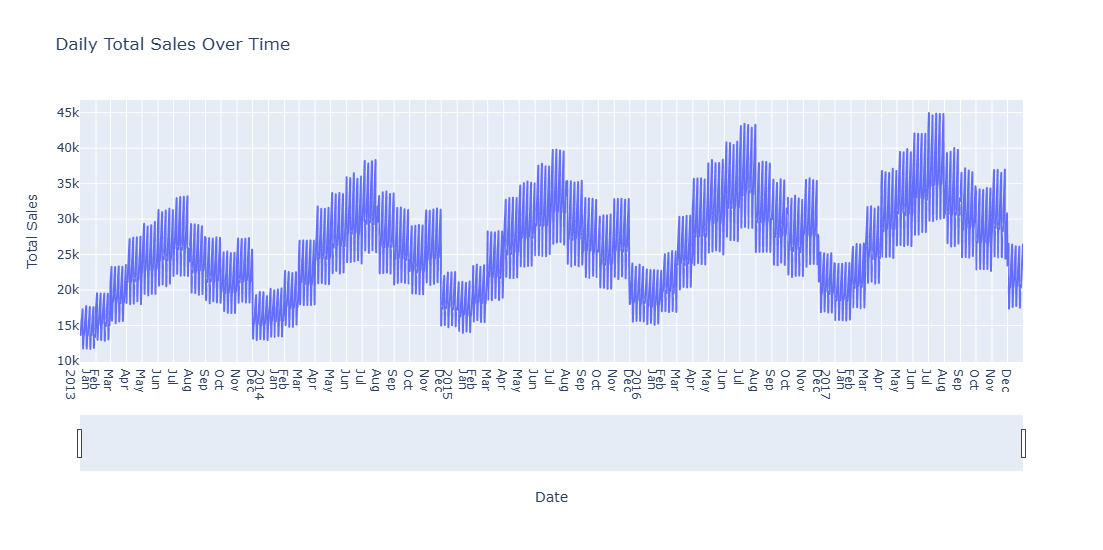

In [4]:
daily_sales = (
    train.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

fig = px.line(
    daily_sales, x="date", y="sales",
    title="Daily Total Sales Over Time"
)
fig.update_xaxes(rangeslider_visible=True, dtick="M1", tickformat="%b\n%Y")
fig.update_layout(xaxis_title="Date", yaxis_title="Total Sales", height=550)
fig.show()

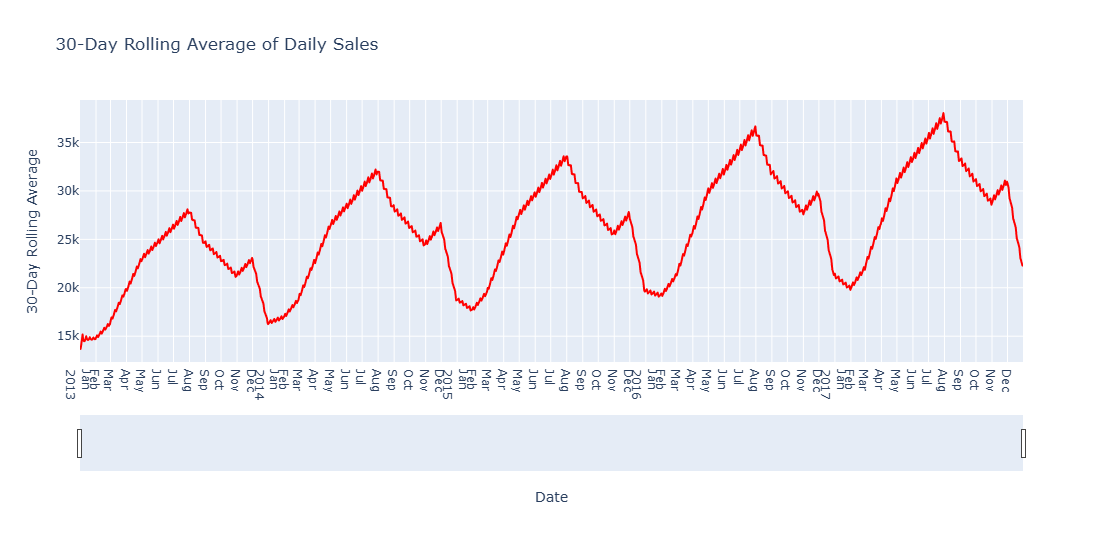

In [5]:
daily_sales["rolling30"] = daily_sales["sales"].rolling(30, min_periods=1).mean()

fig = px.line(
    daily_sales, x="date", y="rolling30",
    title="30-Day Rolling Average of Daily Sales"
)
fig.update_traces(line=dict(color="red", width=2))
fig.update_xaxes(rangeslider_visible=True, dtick="M1", tickformat="%b\n%Y")
fig.update_layout(xaxis_title="Date", yaxis_title="30-Day Rolling Average", height=550)
fig.show()

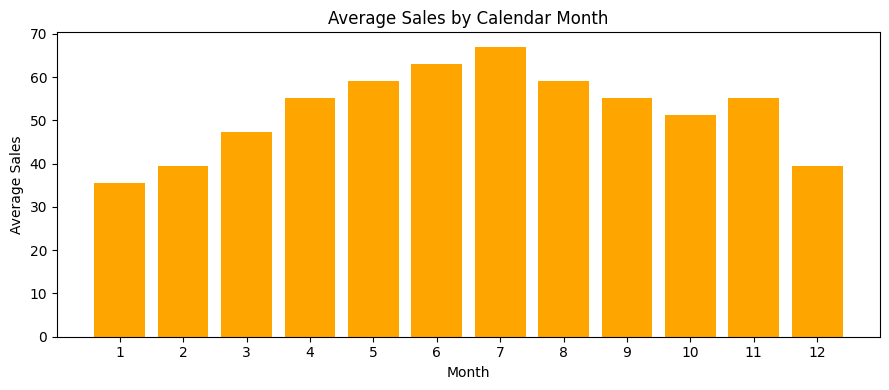

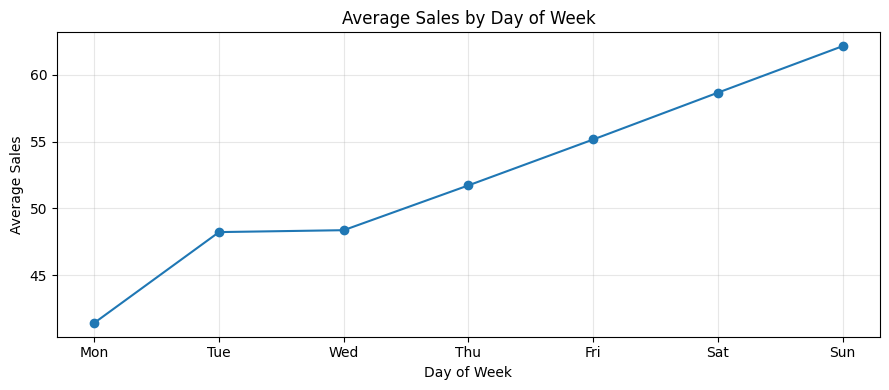

In [6]:
monthly_sales = train.assign(month=train["date"].dt.month).groupby("month")["sales"].mean()
plt.figure(figsize=(9, 4))
plt.bar(monthly_sales.index, monthly_sales.values, color="orange")
plt.title("Average Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

weekday_sales = train.groupby(train["date"].dt.dayofweek)["sales"].mean()
plt.figure(figsize=(9, 4))
plt.plot(weekday_sales.index, weekday_sales.values, marker="o")
plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

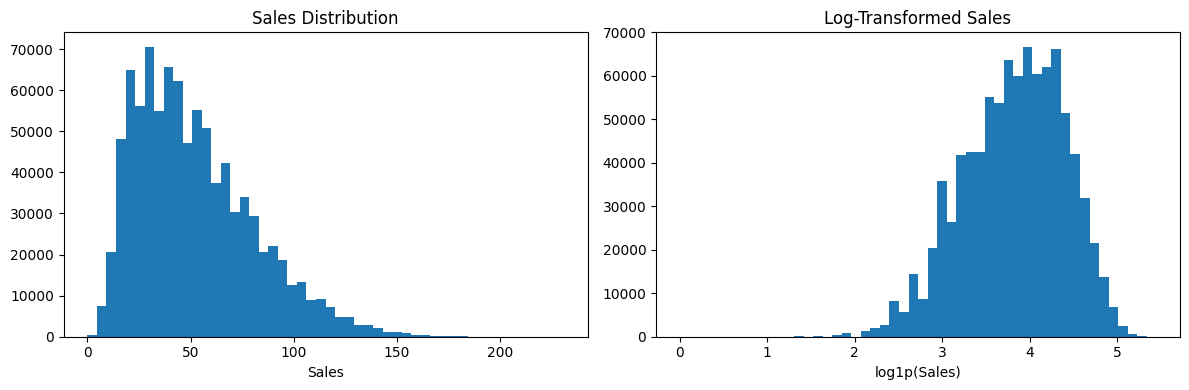

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["sales"], bins=50)
axes[0].set_title("Sales Distribution")
axes[0].set_xlabel("Sales")
axes[1].hist(np.log1p(train["sales"]), bins=50)
axes[1].set_title("Log-Transformed Sales")
axes[1].set_xlabel("log1p(Sales)")
plt.tight_layout()
plt.show()

## 5. Define the evaluation metric
sMAPE is expressed as a percentage. Lower values are better; 0 means perfect predictions.

In [8]:
def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denominator = np.abs(y_true) + np.abs(y_pred)
    errors = np.divide(
        2.0 * np.abs(y_true - y_pred),
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator != 0
    )
    return 100.0 * errors.mean()

## 6. Create features without using future sales
Calendar features describe each date. Store-item averages are calculated from the training data. Lag features use previous observed sales for training rows.

For the validation check, the final 90 days are held out chronologically. The baseline and model comparison below is a useful first check, but lag-based validation features can contain earlier actual values from the validation window. Treat the score as an initial diagnostic rather than a perfect multi-step forecast simulation.

In [9]:
def add_calendar_features(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["day"] = df["date"].dt.day
    df["month"] = df["date"].dt.month
    df["year"] = df["date"].dt.year
    df["dayofweek"] = df["date"].dt.dayofweek
    df["dayofyear"] = df["date"].dt.dayofyear
    df["weekofyear"] = df["date"].dt.isocalendar().week.astype("int16")
    return df

train_fe = add_calendar_features(train)
test_fe = add_calendar_features(test)

# Add store-item historical summary statistics using training data only.
store_item_stats = (
    train.groupby(["store", "item"])["sales"]
    .agg(sales_mean="mean", sales_median="median", sales_std="std")
    .reset_index()
)
store_item_stats["sales_std"] = store_item_stats["sales_std"].fillna(0)

train_fe = train_fe.merge(store_item_stats, on=["store", "item"], how="left")
test_fe = test_fe.merge(store_item_stats, on=["store", "item"], how="left")

# Sort before creating lag features so each lag refers to earlier dates for that store-item series.
train_fe = train_fe.sort_values(["store", "item", "date"]).reset_index(drop=True)
for lag in [7, 14, 28, 365]:
    train_fe[f"lag_{lag}"] = train_fe.groupby(["store", "item"])["sales"].shift(lag)

display(train_fe.head())

,date,store,item,sales,day,month,year,dayofweek,dayofyear,weekofyear,sales_mean,sales_median,sales_std,lag_7,lag_14,lag_28,lag_365
0,2013-01-01,1,1,13,1,1,2013,1,1,1,19.971522,19.0,6.741022,NaN,NaN,NaN,NaN
1,2013-01-02,1,1,11,2,1,2013,2,2,1,19.971522,19.0,6.741022,NaN,NaN,NaN,NaN
2,2013-01-03,1,1,14,3,1,2013,3,3,1,19.971522,19.0,6.741022,NaN,NaN,NaN,NaN
3,2013-01-04,1,1,13,4,1,2013,4,4,1,19.971522,19.0,6.741022,NaN,NaN,NaN,NaN
4,2013-01-05,1,1,10,5,1,2013,5,5,1,19.971522,19.0,6.741022,NaN,NaN,NaN,NaN


## 7. Build a chronological validation split
The last 90 days are validation data. Rows without the minimum one-week history are removed from the training set.

In [10]:
FEATURES = [
    "day", "month", "year", "dayofweek", "dayofyear", "weekofyear",
    "sales_mean", "sales_median", "sales_std",
    "lag_7", "lag_14", "lag_28", "lag_365"
]
TARGET = "sales"

validation_start = train_fe["date"].max() - pd.Timedelta(days=90)

model_data = train_fe.dropna(subset=["lag_7"]).copy()
train_data = model_data[model_data["date"] < validation_start].copy()
val_data = model_data[model_data["date"] >= validation_start].copy()

X_train = train_data[FEATURES].fillna(0)
y_train = train_data[TARGET]
X_val = val_data[FEATURES].fillna(0)
y_val = val_data[TARGET]

print("Validation starts:", validation_start.date())
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Validation starts: 2017-10-02
Training rows: 864000
Validation rows: 45500


## 8. Train and compare baseline models
Compare a global-mean baseline, linear regression, Ridge, Lasso, and XGBoost using the same validation rows.

In [11]:
baseline_results = []

# Simple baseline: predict the mean sales observed in the training split.
global_mean_pred = np.full(len(y_val), y_train.mean())
baseline_results.append({"Model": "Global mean", "sMAPE": smape(y_val, global_mean_pred)})

# Linear models provide reference points before using boosted trees.
for model_name, model in [
    ("Linear Regression", LinearRegression()),
    ("Ridge", Ridge()),
    ("Lasso", Lasso(max_iter=5000))
]:
    model.fit(X_train, y_train)
    prediction = np.clip(model.predict(X_val), 0, None)
    baseline_results.append({"Model": model_name, "sMAPE": smape(y_val, prediction)})

dtrain = xgb.DMatrix(X_train, label=np.log1p(y_train), feature_names=FEATURES)
dval = xgb.DMatrix(X_val, feature_names=FEATURES)

xgb_params = {
    "objective": "reg:squarederror",
    "eta": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "seed": RANDOM_STATE
}

xgb_baseline = xgb.train(xgb_params, dtrain, num_boost_round=500, verbose_eval=False)
xgb_val_pred = np.clip(np.expm1(xgb_baseline.predict(dval)), 0, None)
baseline_results.append({"Model": "XGBoost", "sMAPE": smape(y_val, xgb_val_pred)})

baseline_results = pd.DataFrame(baseline_results).sort_values("sMAPE").reset_index(drop=True)
display(baseline_results)

,Model,sMAPE
0,XGBoost,12.489964
1,Lasso,15.795927
2,Ridge,16.031848
3,Linear Regression,16.032782
4,Global mean,44.184619


## 9. Tune XGBoost hyperparameters
A small randomized search tries several configurations. Increase `N_TRIALS` for a longer search.

In [12]:
import random

N_TRIALS = 20
rng = random.Random(RANDOM_STATE)

param_grid = {
    "eta": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [4, 5, 6, 7, 8],
    "subsample": [0.6, 0.7, 0.8, 0.9],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "min_child_weight": [1, 3, 5, 7],
    "lambda": [0, 0.1, 1, 2],
    "alpha": [0, 0.1, 1]
}

best_params = None
best_validation_smape = float("inf")
best_rounds = 500
tuning_results = []

for trial in range(N_TRIALS):
    params = {
        "objective": "reg:squarederror",
        "eta": rng.choice(param_grid["eta"]),
        "max_depth": rng.choice(param_grid["max_depth"]),
        "subsample": rng.choice(param_grid["subsample"]),
        "colsample_bytree": rng.choice(param_grid["colsample_bytree"]),
        "min_child_weight": rng.choice(param_grid["min_child_weight"]),
        "lambda": rng.choice(param_grid["lambda"]),
        "alpha": rng.choice(param_grid["alpha"]),
        "seed": RANDOM_STATE
    }

    candidate = xgb.train(params, dtrain, num_boost_round=500, verbose_eval=False)
    candidate_pred = np.clip(np.expm1(candidate.predict(dval)), 0, None)
    score = smape(y_val, candidate_pred)
    tuning_results.append({"trial": trial + 1, "sMAPE": score, **params})

    if score < best_validation_smape:
        best_validation_smape = score
        best_params = params

    print(f"Trial {trial + 1}/{N_TRIALS}: sMAPE = {score:.3f}%")

tuning_results = pd.DataFrame(tuning_results).sort_values("sMAPE").reset_index(drop=True)
print(f"Best validation sMAPE: {best_validation_smape:.3f}%")
print("Best parameters:", best_params)
display(tuning_results.head())

Trial 1/20: sMAPE = 13.722%
Trial 2/20: sMAPE = 12.894%
Trial 3/20: sMAPE = 12.791%
Trial 4/20: sMAPE = 12.747%
Trial 5/20: sMAPE = 12.668%
Trial 6/20: sMAPE = 12.372%
Trial 7/20: sMAPE = 12.896%
Trial 8/20: sMAPE = 12.667%
Trial 9/20: sMAPE = 12.380%
Trial 10/20: sMAPE = 12.748%
Trial 11/20: sMAPE = 12.419%
Trial 12/20: sMAPE = 12.423%
Trial 13/20: sMAPE = 12.408%
Trial 14/20: sMAPE = 12.395%
Trial 15/20: sMAPE = 12.506%
Trial 16/20: sMAPE = 12.419%
Trial 17/20: sMAPE = 12.385%
Trial 18/20: sMAPE = 12.407%
Trial 19/20: sMAPE = 12.449%
Trial 20/20: sMAPE = 12.449%
Best validation sMAPE: 12.372%
Best parameters: {'objective': 'reg:squarederror', 'eta': 0.05, 'max_depth': 8, 'subsample': 0.8, 'colsample_bytree': 0.6, 'min_child_weight': 7, 'lambda': 0, 'alpha': 0.1, 'seed': 42}


,trial,sMAPE,objective,eta,max_depth,subsample,colsample_bytree,min_child_weight,lambda,alpha,seed
0,6,12.371785,reg:squarederror,0.05,8,0.8,0.6,7,0.0,0.1,42
1,9,12.379552,reg:squarederror,0.10,6,0.7,0.8,5,0.1,1.0,42
2,17,12.384856,reg:squarederror,0.05,8,0.6,0.6,5,1.0,0.0,42
3,14,12.395122,reg:squarederror,0.05,8,0.9,0.9,5,0.1,0.0,42
4,18,12.406649,reg:squarederror,0.05,7,0.7,0.9,1,1.0,1.0,42


## 10. Evaluate the tuned model
This score is calculated on the held-out validation rows.

In [13]:
tuned_model = xgb.train(best_params, dtrain, num_boost_round=500, verbose_eval=False)
tuned_val_pred = np.clip(np.expm1(tuned_model.predict(dval)), 0, None)
tuned_validation_smape = smape(y_val, tuned_val_pred)

print(f"Tuned XGBoost validation sMAPE: {tuned_validation_smape:.3f}%")

Tuned XGBoost validation sMAPE: 12.372%


## 11. Train the final model and forecast the test dates
For the final model, train on all rows that have lag history. Test lags are created sequentially: once a date is predicted, those predictions become the history used for later test dates. This is important when forecasting multiple future days.

In [14]:
# Fit the final model on all training rows with available one-week lag history.
full_train = train_fe.dropna(subset=["lag_7"]).copy()
X_full = full_train[FEATURES].fillna(0)
y_full = full_train[TARGET]

dfull = xgb.DMatrix(X_full, label=np.log1p(y_full), feature_names=FEATURES)
final_model = xgb.train(best_params, dfull, num_boost_round=500, verbose_eval=False)

print("Final XGBoost model trained on", len(full_train), "rows.")

Final XGBoost model trained on 909500 rows.


In [15]:
# Prepare an indexed history of known training sales.
history = train[["date", "store", "item", "sales"]].copy()
history["date"] = pd.to_datetime(history["date"])
history = history.sort_values(["store", "item", "date"])

test_forecast = test_fe.sort_values(["date", "store", "item"]).copy()
test_forecast["sales_prediction"] = np.nan

# Predict one date at a time so later test dates can use earlier predictions as lag values.
for forecast_date in sorted(test_forecast["date"].dropna().unique()):
    date_mask = test_forecast["date"].eq(forecast_date)
    rows = test_forecast.loc[date_mask].copy()

    for lag in [7, 14, 28, 365]:
        lag_dates = rows["date"] - pd.Timedelta(days=lag)
        lookup = history.set_index(["date", "store", "item"])["sales"]
        keys = pd.MultiIndex.from_arrays(
            [lag_dates, rows["store"], rows["item"]],
            names=["date", "store", "item"]
        )
        rows[f"lag_{lag}"] = lookup.reindex(keys).to_numpy()

    X_day = rows[FEATURES].fillna(0)
    dday = xgb.DMatrix(X_day, feature_names=FEATURES)
    day_prediction = np.clip(np.expm1(final_model.predict(dday)), 0, None)

    test_forecast.loc[date_mask, "sales_prediction"] = day_prediction

    # Add this date's predictions to history for forecasting later dates.
    predicted_history = rows[["date", "store", "item"]].copy()
    predicted_history["sales"] = day_prediction
    history = pd.concat([history, predicted_history], ignore_index=True)

test_pred = test_forecast["sales_prediction"].to_numpy()
print("Number of predictions:", len(test_pred))
print("All predictions finite:", np.isfinite(test_pred).all())

Number of predictions: 45000
All predictions finite: True


## 12. Create the submission file
Keep the sample submission's ID/order intact and replace only the target column.

In [16]:
if len(test_pred) != len(sample_submission):
    raise ValueError(
        f"Prediction count ({len(test_pred)}) does not match "
        f"sample submission rows ({len(sample_submission)})."
    )

submission = sample_submission.copy()
submission["sales"] = test_pred
submission.to_csv("submission.csv", index=False)

print("Saved submission.csv")
display(submission.head())

Saved submission.csv


,id,sales
0,0,11.316800
1,1,30.860374
2,2,19.764738
3,3,11.183389
4,4,9.708430


## 13. Save the trained model
The XGBoost model is saved locally so it can be loaded later without retraining.

In [18]:
final_model.save_model("tuned_xgboost_model1.json")
print("Saved tuned_xgboost_model1.json")

Saved tuned_xgboost_model1.json


## 14. Optional: load the saved model
Run this cell in a later session if you want to reuse the saved model.

In [19]:
loaded_model = xgb.Booster()
loaded_model.load_model("tuned_xgboost_model.json")
print("Saved model loaded successfully.")

Saved model loaded successfully.



## Conclusion and Business Impact

This project developed an end-to-end sales forecasting pipeline using historical store-item sales data and XGBoost regression.

### Project Scale
- **913,000 historical sales records** used for model development.
- **10 stores and 50 unique items** represented in the dataset.
- **5 years of daily sales history** analyzed to identify trends, seasonality, and demand patterns.
- **4 lag-based features** (7, 14, 28, and 365 days) engineered to capture historical sales behavior.

### Business Impact
1. **Inventory Optimization:** Forecasting demand at the store-item level can help businesses reduce overstocking, minimize stockouts, and improve inventory allocation.
2. **Better Demand Planning:** Daily forecasts help store managers anticipate changes in demand and plan replenishment more effectively.
3. **Data-Driven Decisions:** Monthly seasonality, weekday patterns, and historical sales trends can support purchasing and operational planning.
4. **Scalable Forecasting:** An automated prediction pipeline can generate forecasts across multiple stores and products, reducing repetitive manual analysis.
5. **Reusable Machine Learning Pipeline:** The trained model is saved as `tuned_xgboost_model.json`, and predictions are exported to `submission.csv` for downstream use.

### Final Outcome
The project demonstrates how historical sales data can be transformed into a structured forecasting workflow using data analysis, feature engineering, chronological validation, sMAPE evaluation, and XGBoost.

The potential business value is improved demand visibility and more informed inventory decisions. Actual reductions in stockouts, excess inventory, or operating costs would need to be measured through a real-world deployment and compared against existing forecasting practices.

**Next Steps:** Improve validation for multi-day forecasting, incorporate holidays and promotional data, compare against seasonal-naive baselines, and monitor forecast accuracy over time.
